# B2_citra_warna: Evaluasi Praktikum P1-P4 Computer Vision (SIMUTEH)
**Nama:** Rian | **NIM:** 2330511025 | **SEED:** 1025 | **Kelas:** 6A

Membutuhkan dataset dari B1. Mengerjakan lembar hitung 2.1, kanal warna, sampling dan kuantisasi, Tabel 8, serta P2.1 sampai P2.6.

> Angka pada teks jawaban berasal dari satu kali jalan dengan SEED 1025. Nilai KB dan PSNR deterministik; **waktu (ms)** bergantung mesin, jadi cocokkan dengan keluaran milikmu.

## Bagian 2. Pembentukan Citra dan Ruang Warna

In [1]:
import os, sys
# Jalankan dari folder notebook/ di dalam repository (jalur file selalu diawali ../).
if os.path.basename(os.getcwd()) != "notebook":
    cand = "/content/simuteh-2330511025/notebook"
    if os.path.exists(cand): os.chdir(cand)
    else: raise SystemExit("Buka notebook ini dari folder notebook/ di repository (di Colab: git clone repo-mu dahulu, lalu %cd simuteh-2330511025/notebook).")
sys.path.append("../src")
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd, time
from matplotlib.patches import FancyBboxPatch
from utils_cv import baca, tampil, kontras_bercak, statistik
if not os.path.exists("../data/sintetis/label.csv"):
    raise SystemExit("Dataset belum ada. Jalankan B1_lingkungan.ipynb dahulu (atau: cd .. lalu python src/buat_dataset_sintetis.py).")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
print("Folder kerja:", os.getcwd(), "| citra:", len(label))

Folder kerja: /tmp/repo/simuteh-2330511025/notebook | citra: 60


### Langkah 2.1 Lembar hitung manual (langkah, substitusi, satuan)

Rumus proyeksi pinhole: $x = f\,X / Z$. Data: f = 4,0 mm; piksel sensor 0,0014 mm; X = 5 mm; Z = 300 mm.

**a)** $x = 4{,}0 \times 5 / 300 = 0{,}0667$ mm. Jumlah piksel $= 0{,}0667 / 0{,}0014 = 47{,}6$ piksel.

**b)** Z = 600 mm: $x = 4{,}0 \times 5 / 600 = 0{,}0333$ mm, yaitu $0{,}0333/0{,}0014 = 23{,}8$ piksel. Jarak dua kali lebih jauh membuat bercak setengah lebih kecil: ukuran bayangan **berbanding terbalik** dengan jarak.

**c)** Syarat 10 piksel berarti $x = 10 \times 0{,}0014 = 0{,}014$ mm. Maka $Z = fX/x = 4{,}0 \times 5 / 0{,}014 = 1428{,}6$ mm (sekitar 1,43 m) pada foto resolusi penuh.

**d)** Faktor perkecilan $= 640/4000 = 0{,}16$. Diameter setelah diperkecil (Z = 300 mm): $47{,}6 \times 0{,}16 = 7{,}6$ piksel, **kurang dari 10**. Ukuran piksel efektif menjadi $0{,}0014/0{,}16 = 0{,}00875$ mm, sehingga jarak maksimum agar tetap 10 piksel: $Z = 4{,}0 \times 5 / (10 \times 0{,}00875) = 228{,}6$ mm (sekitar 23 cm).

**e)** Memori tanpa kompresi:
- Foto asli: $4000 \times 3000 \times 3 = 36{.}000{.}000$ byte $= 36$ MB (sekitar 34,3 MiB).
- Citra 640 x 480 berwarna: $640 \times 480 \times 3 = 921{.}600$ byte $= 900$ KiB.
- Citra 640 x 480 keabuan: $640 \times 480 = 307{.}200$ byte $= 300$ KiB.
- 300 foto asli: $300 \times 36$ MB $= 10{.}800$ MB $= 10{,}8$ GB.

**f)** $Y = 0{,}299R + 0{,}587G + 0{,}114B$.
- Bercak (196, 178, 86): $58{,}60 + 104{,}49 + 9{,}80 = 172{,}9 \approx 173$.
- Daun (52, 136, 60): $15{,}55 + 79{,}83 + 6{,}84 = 102{,}2 \approx 102$.
- Selisih $= 70{,}7 \approx 71$. Hasil `cv2.cvtColor` di bawah menghasilkan 173 dan 102 (cocok), dan Hue OpenCV bercak = 25, daun = 63 (rentang 0 sampai 179).

In [2]:
# Pemeriksaan lembar hitung 2.1 dengan kode
f, px, X = 4.0, 0.0014, 5
for Z in (300, 600):
    x = f * X / Z; print(f"Z={Z} mm: x={x:.4f} mm = {x/px:.1f} piksel")
print("c) Z maks (10 px, resolusi penuh):", f*X/(10*px), "mm")
skala = 640/4000
print("d) diameter setelah resize:", f*X/300/px*skala, "px | Z maks:", f*X/(10*px/skala), "mm")
print("e) asli:", 4000*3000*3/1e6, "MB | 640x480 warna:", 640*480*3/1024, "KiB | abu:", 640*480/1024, "KiB | 300 foto:", 300*4000*3000*3/1e9, "GB")
pik = np.array([[[86, 178, 196], [60, 136, 52]]], np.uint8)   # urutan BGR
print("gray OpenCV:", cv2.cvtColor(pik, cv2.COLOR_BGR2GRAY).ravel(), "| HSV OpenCV (bercak, daun):", cv2.cvtColor(pik, cv2.COLOR_BGR2HSV)[0].tolist())

Z=300 mm: x=0.0667 mm = 47.6 piksel
Z=600 mm: x=0.0333 mm = 23.8 piksel
c) Z maks (10 px, resolusi penuh): 1428.5714285714284 mm
d) diameter setelah resize: 7.6190476190476195 px | Z maks: 228.57142857142858 mm
e) asli: 36.0 MB | 640x480 warna: 900.0 KiB | abu: 300.0 KiB | 300 foto: 10.8 GB
gray OpenCV: [173 102] | HSV OpenCV (bercak, daun): [[25, 143, 196], [63, 158, 136]]


### Langkah 2.2 Rencana akuisisi citra (Tabel)

| Butir | Rencana |
|---|---|
| Jarak pemotretan | 20 sampai 22 cm di atas daun (maksimum 22,9 cm dari hitungan 2.1 d) |
| Sudut | Tegak lurus (kamera menghadap ke bawah, sejajar nampan), hindari miring agar skala seragam |
| Resolusi minimum | Foto asli 12 MP (4000 x 3000), tanpa zoom digital; diperkecil ke lebar 640 setelah diambil |
| Alas dan acuan ukuran | Nampan anyaman berwarna polos seragam; tempel penggaris atau kotak acuan 5 cm di tepi nampan |
| Kondisi cahaya | Sampel mewakili lima kondisi: normal, gelap, terik, berkabut/kontras rendah, bayangan sebagian |
| Jumlah citra per kelas | Minimal 20 per kelas (sehat, ringan, berat) x 5 kondisi = 100 citra per kelas untuk penelitian lanjutan |
| Penamaan berkas | `teh_<nomor>_<kelas>_<kondisi>.jpg` tanpa nama petani atau lokasi |
| Izin | Persetujuan tertulis kelompok tani; tujuan dan pemakaian data dijelaskan |
| Metadata | Hapus EXIF (GPS, waktu, model ponsel) sebelum disimpan atau diunggah |
| Larangan | Tidak boleh ada wajah, tangan beridentitas, atau papan nama di dalam bingkai |

### Langkah 2.3 Kanal warna (Kode 2.1), teh_041 (berat, normal)

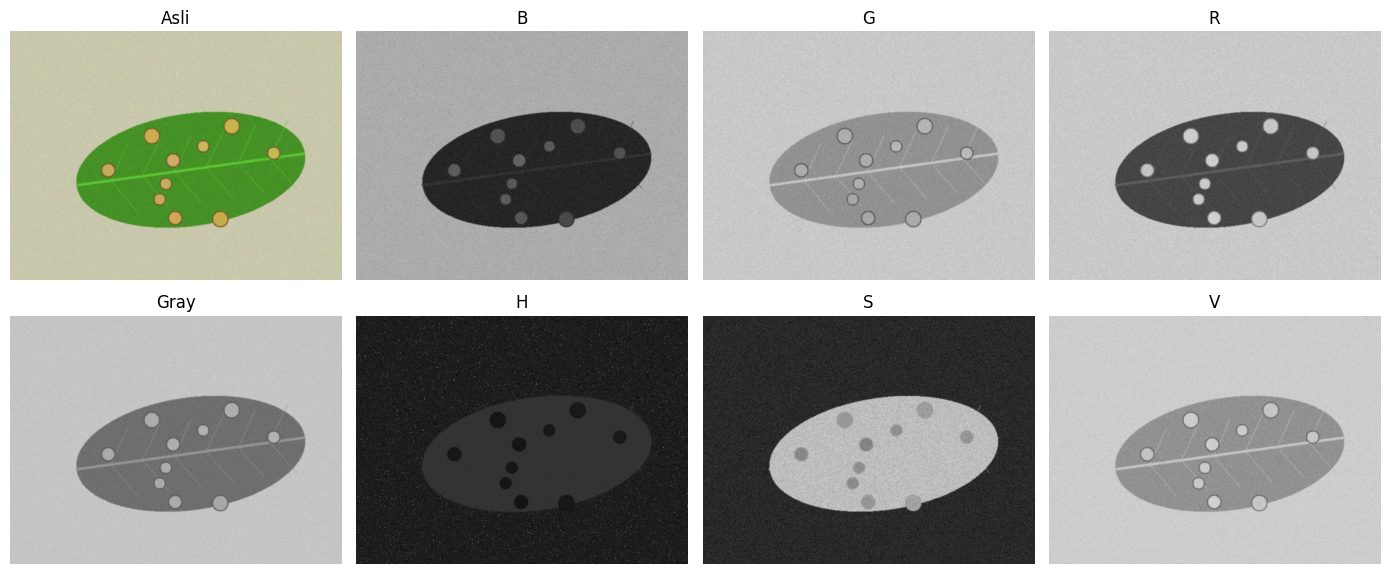

KB kanal B   : 3.88
KB kanal G   : 0.43
KB kanal R   : 10.93
KB kanal Gray: 4.45
KB kanal H   : 9.84
KB kanal S   : 2.54
KB kanal V   : 2.52


In [3]:
nama = "teh_041.png"
img = baca(f"../data/sintetis/citra/{nama}")
md_ = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png"); plt.show()
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md_, mb):.2f}")

### Langkah 2.4 Eksperimen sampling dan kuantisasi (Kode 2.2) dengan tampilan visual

== Sampling ==
fx=0.5: ukuran (240, 320), KB=4.95
fx=0.2: ukuran (96, 128), KB=4.43
fx=0.1: ukuran (48, 64), KB=3.17
fx=0.05: ukuran (24, 32), KB=1.54


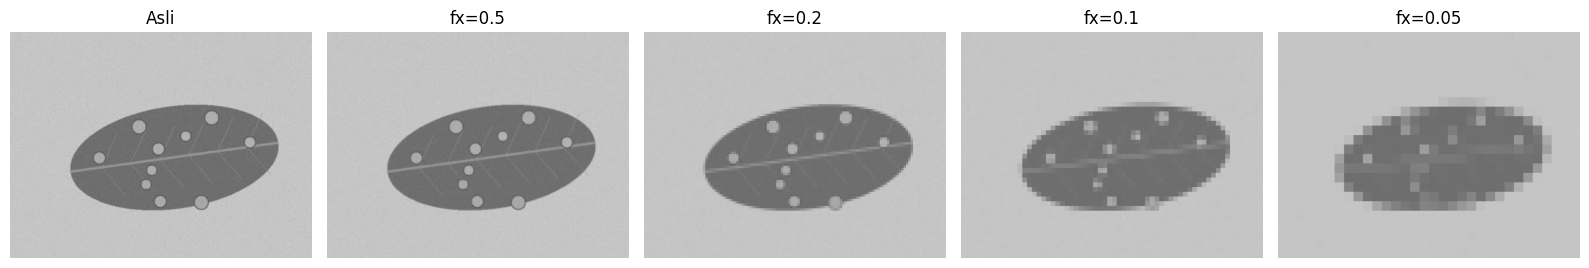

== Kuantisasi ==
k=1: 2 level, KB=3.23
k=2: 3 level, KB=3.23
k=3: 5 level, KB=5.47
k=4: 10 level, KB=3.65
k=8: 146 level, KB=4.45


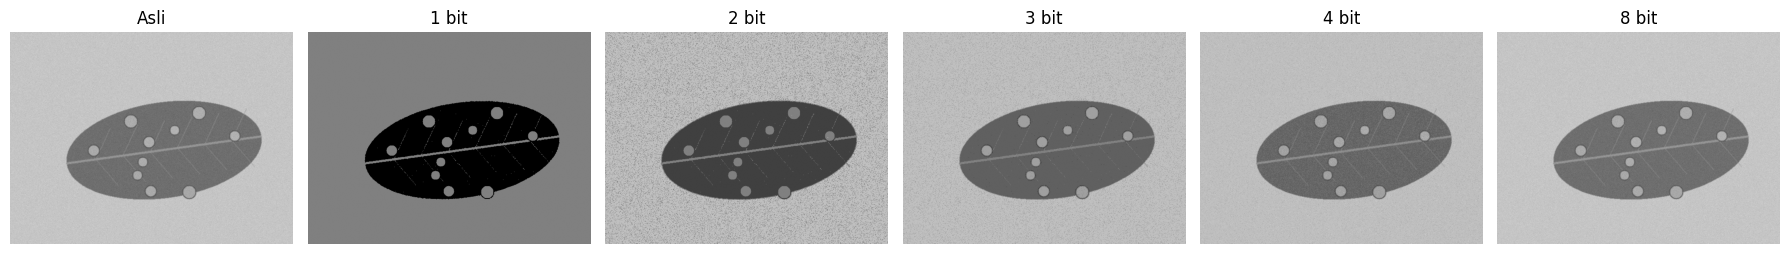

In [4]:
daftar, judul = [gray], ["Asli"]
print("== Sampling ==")
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md_, mb):.2f}")
    daftar.append(besar); judul.append(f"fx={fx}")
tampil(daftar, judul, baris=1, ukuran=(16, 3)); plt.savefig("../hasil/b2_sampling.png"); plt.show()
daftar, judul = [gray], ["Asli"]
print("== Kuantisasi ==")
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k); kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md_, mb):.2f}")
    daftar.append(kuant); judul.append(f"{k} bit")
tampil(daftar, judul, baris=1, ukuran=(18, 3)); plt.savefig("../hasil/b2_kuantisasi.png"); plt.show()

### Langkah 2.5 dan 2.6 Rerata KB per kanal dan kondisi (Kode 2.3), kelas berat dan kelas ringan


=== Tabel 8: rerata KB kelas berat ===
                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          3.06  0.85  10.39  4.67  8.57  1.90  2.56
gelap           1.41  0.64  10.59  3.85  6.70  1.52  2.26
terang          2.46  1.04   7.74  4.42  5.83  1.21  2.39
kontras_rendah  1.06  0.34   4.17  2.22  2.29  0.42  1.32
bayangan        1.40  0.38   4.75  1.58  4.18  0.89  0.94



=== Tabel 8: rerata KB kelas ringan ===
                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.27  1.05  9.44  3.21  8.88  1.20  1.59
gelap           0.86  0.46  7.39  2.63  5.02  0.91  1.77
terang          1.79  0.36  5.05  2.15  4.31  1.22  0.77
kontras_rendah  0.37  0.32  2.83  1.13  1.39  0.22  0.72
bayangan        0.67  0.25  4.32  1.12  4.03  0.65  0.54


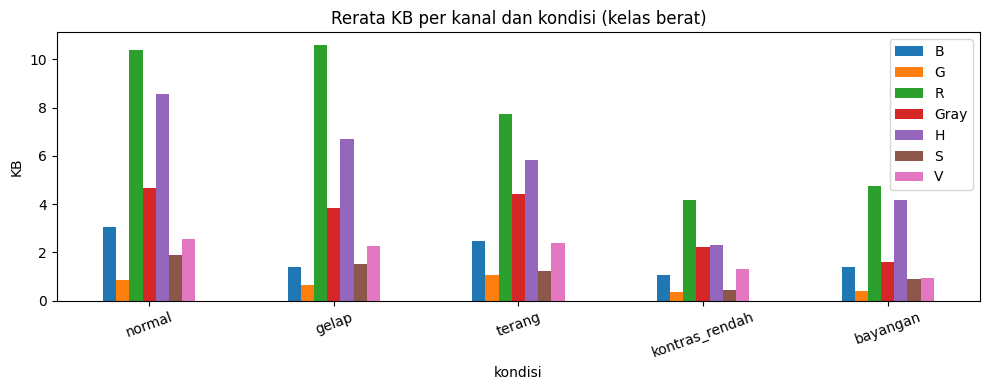

Kanal terbaik per kondisi (berat): {'normal': 'R', 'gelap': 'R', 'terang': 'R', 'kontras_rendah': 'R', 'bayangan': 'R'}
Kanal terbaik per kondisi (ringan): {'normal': 'R', 'gelap': 'R', 'terang': 'R', 'kontras_rendah': 'R', 'bayangan': 'R'}


In [5]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r, "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), "H": h, "S": s, "V": v}
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
tabel = {}
for kls in ["berat", "ringan"]:
    baris = []
    for _, d in label[label.kelas == kls].iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya; baris.append(kb)
    tabel[kls] = pd.DataFrame(baris).groupby("kondisi").mean().round(2).loc[URUT]
    tabel[kls].to_csv(f"../hasil/b2_kb_kanal_{kls}.csv")
    print(f"\n=== Tabel 8: rerata KB kelas {kls} ==="); print(tabel[kls])
tabel["berat"].plot(kind="bar", figsize=(10, 4), title="Rerata KB per kanal dan kondisi (kelas berat)")
plt.ylabel("KB"); plt.xticks(rotation=20); plt.tight_layout(); plt.savefig("../hasil/b2_grafik_kb.png"); plt.show()
print("Kanal terbaik per kondisi (berat):", tabel["berat"].idxmax(axis=1).to_dict())
print("Kanal terbaik per kondisi (ringan):", tabel["ringan"].idxmax(axis=1).to_dict())

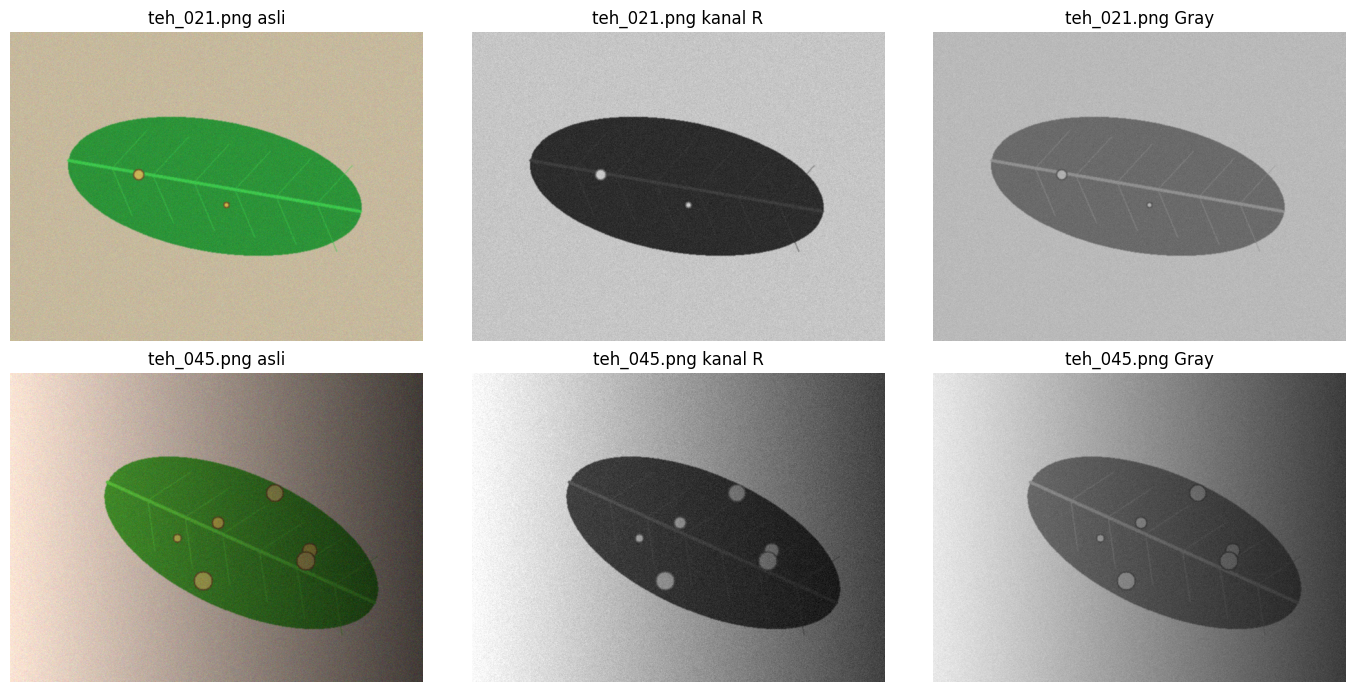

In [6]:
# Panel kanal terbaik: teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
fig_list, fig_jd = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    fig_list += [im, im[:, :, 2], cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)]
    fig_jd += [f"{nm} asli", f"{nm} kanal R", f"{nm} Gray"]
tampil(fig_list, fig_jd, baris=2, ukuran=(14, 7)); plt.savefig("../hasil/b2_panel_terbaik.png"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 2

**P2.1 Aturan pemotretan.** Dari 2.1 d), setelah diperkecil ke lebar 640, bercak 5 mm hanya 7,6 piksel pada jarak 30 cm (di bawah syarat 10 piksel); jarak maksimum agar tetap 10 piksel adalah 22,9 cm. Bidang pandang pada jarak itu sekitar 32 cm (lebar sensor 5,6 mm / f 4 mm x 228 mm), cukup untuk satu daun di atas nampan. **Aturan untuk petugas:** *"Pegang ponsel tegak lurus sekitar satu jengkal (20 cm) di atas daun, jangan lebih jauh dari 22 cm, pakai kamera resolusi penuh 12 MP, tanpa zoom."* Bila ingin memotret lebih jauh, resolusi kerja harus dinaikkan (mis. lebar 1280 piksel memberi jarak maksimum sekitar 45 cm).

**P2.2 Kanal terbaik.** Kanal **R** memberi KB tertinggi di kelima kondisi (kelas berat: normal 10,39; gelap 10,59; terang 7,74; kontras rendah 4,17; bayangan 4,75), dan juga pada kelas ringan. Penjelasan fisik: klorofil daun menyerap merah dan biru dan memantulkan terutama hijau, sehingga R daun rendah (sekitar 52). Bercak pucat kekuningan memantulkan merah dan hijau sekaligus, sehingga R bercak tinggi (sekitar 196): selisih sekitar 144 tingkat. Pada kanal G daun dan bercak sama-sama cukup terang (136 dan 178), selisihnya kecil sehingga KB G hanya 0,34 sampai 1,04. Kanal B berselisih sedikit (60 vs 86).

**P2.3 Apakah H tahan cahaya?** Hasil mendukung **sebagian**. KB kanal H lebih tinggi dari V di semua kondisi, tetapi tidak kebal: H turun dari 8,57 (normal) menjadi 6,70 (gelap, turun 22%), 5,83 (terang, turun 32%), dan 4,18 (bayangan, turun 51%). V turun dari 2,56 menjadi 2,26 (gelap), 2,39 (terang), dan 0,94 (bayangan, turun 63%). Jadi H jauh lebih informatif daripada V karena V memang mengukur kecerahan, tetapi Hue tidak sepenuhnya invarian: pada piksel gelap atau jenuh, derau membuat rasio kanal tidak stabil, dan Hue mudah bergeser.

**P2.4 Kuantisasi dan keterbatasan KB.** Tidak. Pada teh_041, KB 3 bit (5 level) = 5,47, lebih tinggi daripada 8 bit (146 level) = 4,45, padahal citra 3 bit tampak berpita (*banding*), tulang daun dan gradasi hilang. KB hanya membandingkan rerata bercak dan daun terhadap simpangan baku daun; kuantisasi kasar meratakan variasi daun (penyebut mengecil) sehingga KB naik, walau informasi visual hilang. KB tidak mengukur kemiripan bentuk, tepi, atau tekstur, jadi harus dipasangkan dengan pemeriksaan visual dan ukuran lain.

**P2.5 Sampling.** KB turun dari 4,95 (fx=0,5) ke 4,43 (0,2), 3,17 (0,1), dan 1,54 (0,05). Pada panel `b2_sampling.png` (teh_041), sampai fx=0,2 semua bercak masih tampak jelas. Pada **fx=0,1** (lebar 64 piksel) bercak mulai sulit dibedakan: berubah menjadi blok kasar 1 sampai 3 piksel dengan tepi kabur dan bercak terkecil nyaris menyatu dengan daun; pada fx=0,05 sebagian besar bercak hilang. Secara hitungan, bercak berat berdiameter sekitar 14 sampai 32 piksel (radius 5 sampai 14 ditambah tepi 2) dan bercak ringan 10 sampai 18 piksel pada citra 640 piksel; pada fx=0,1 menjadi 1 sampai 3 piksel dan 1 sampai 2 piksel. Ini konsisten dengan hitungan 2.1 d): bercak yang kurang dari sekitar 10 piksel sudah berada di ambang terlihat. *(Cocokkan dengan gambar milikmu sendiri.)*

**P2.6 Risiko EXIF.** EXIF dapat membocorkan koordinat GPS (lokasi kebun), tanggal dan jam pemotretan (pola kerja), model dan nomor seri ponsel, kadang nama pemilik dan gambar mini. Yang dirugikan: petani (lokasi kebun dan kebiasaannya diketahui orang luar, risiko pencurian atau penekanan harga) dan kelompok tani. Rencana akuisisi mencegahnya dengan menghapus EXIF sebelum disimpan, repository privat, penamaan berkas tanpa nama atau lokasi, dan izin tertulis.